# Phase 1 (Grade 3.0) — Basic Unconditional GAN on EMNIST Letters

> **Team Members:** `[Student 1 Name — Student ID]` & `[Student 2 Name — Student ID]`  
> **Course:** Deep Learning Labs (PUT)  
> **Goal:** Implement and train an unconditional Generative Adversarial Network (GAN) that generates realistic `28x28` handwritten letter images from random noise.

### Notebook Outline
1. **Dataset Exploration & Pitfalls** — fixing EMNIST's transposed orientation and 1-indexed labels.
2. **Trial 1: MLP GAN (Baseline)** — a simple fully connected GAN to establish a baseline and observe its limitations.
3. **Trial 2: Compact DCGAN** — upgrading to convolutional layers and one-sided label smoothing, then diagnosing why $D$ overpowered $G$.
4. **Trial 3: Balanced SpectralNorm + Resize-Conv DCGAN (Final Phase 1 Model)** — fixing $G$/$D$ equilibrium and global letter structure.
5. **Final Showcase & Latent Space Interpolation** — checking visual quality, diversity, and smoothness of the learned latent space.

In [1]:
import sys
from pathlib import Path

# Ensure the repository root is on sys.path whether Jupyter starts in root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch

from src.dataset import get_emnist_dataloader, get_emnist_dataset, label_to_letter
from src.models import (
    BalancedDCGANDiscriminator,
    DCGANDiscriminator,
    DCGANGenerator,
    MLPDiscriminator,
    MLPGenerator,
    RefinedDCGANGenerator,
    init_gan_weights,
)
from src.train import train_unconditional_gan
from src.utils import (
    denormalize,
    get_device,
    plot_training_losses,
    save_checkpoint,
    set_seed,
    show_image_grid,
)

DATA_DIR = PROJECT_ROOT / "data"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase1"

set_seed(42)
device = get_device()
print(f"Project root: {PROJECT_ROOT}")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

/home/mateusz/code/GAN/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /home/mateusz/code/GAN
Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Laptop GPU


## 1. Exploring EMNIST Letters & Fixing Dataset Quirks

Before training any GAN, we inspected real samples from `torchvision.datasets.EMNIST(split="letters")` and caught **two common pitfalls**:

1. **Transposed image orientation:** By default, EMNIST images come rotated 90° and flipped horizontally (a carryover from the original MATLAB format). Transposing the height and width axes makes all letters upright.
2. **1-indexed labels:** Class `0` is unused (`N/A`), and letters `'A'..'Z'` are numbered `1..26`. Shifting labels by `-1` maps them cleanly to `0..25` (important for Phase 2 embeddings).
3. **Pixel range `[-1, 1]`:** We normalize images with `mean=0.5, std=0.5` so real data matches our Generator's `Tanh()` output range.

Below we visualize the raw images vs. the fixed images to confirm our preprocessing pipeline.

Training set size: 124,800 images
Single image shape: (1, 28, 28)
Pixel value range: [-1.00, 1.00]
Shifted label range: 6..25 (letters: ['W', 'G', 'P', 'O', 'W', 'Q', 'M', 'K'])


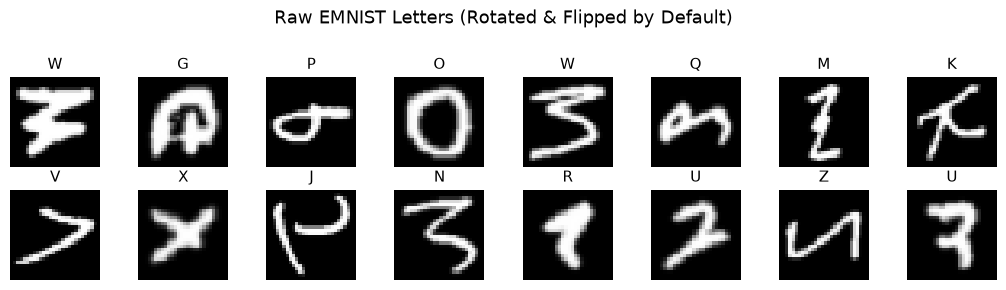

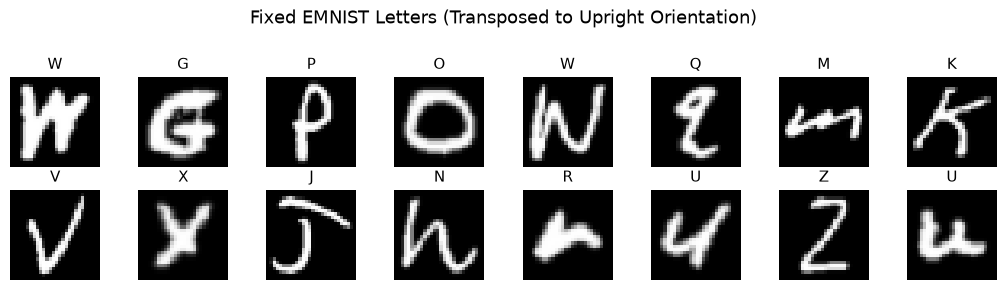

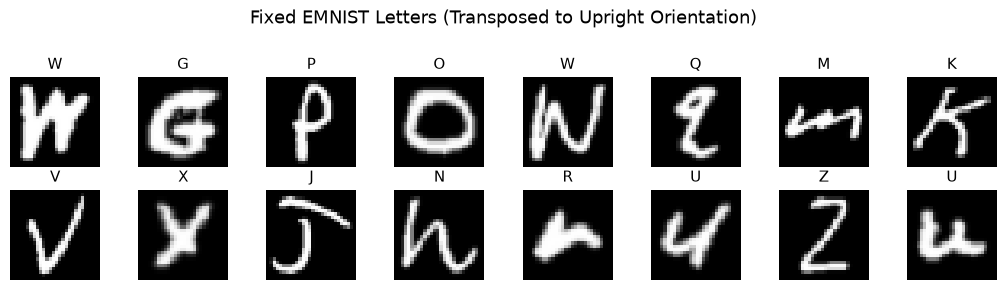

In [2]:
raw_dataset = get_emnist_dataset(root=DATA_DIR, train=True, download=True, fix_orientation=False)
fixed_dataset = get_emnist_dataset(root=DATA_DIR, train=True, download=True, fix_orientation=True)

sample_indices = list(range(16))
raw_images = torch.stack([raw_dataset[i][0] for i in sample_indices])
fixed_images = torch.stack([fixed_dataset[i][0] for i in sample_indices])
sample_labels = [int(fixed_dataset[i][1]) for i in sample_indices]

print(f"Training set size: {len(fixed_dataset):,} images")
print(f"Single image shape: {tuple(fixed_images[0].shape)}")
print(f"Pixel value range: [{fixed_images.min():.2f}, {fixed_images.max():.2f}]")
print(f"Shifted label range: {min(sample_labels)}..{max(sample_labels)} (letters: {[label_to_letter(y) for y in sample_labels[:8]]})")

show_image_grid(
    raw_images,
    labels=sample_labels,
    nrow=8,
    title="Raw EMNIST Letters (Rotated & Flipped by Default)",
)
show_image_grid(
    fixed_images,
    labels=sample_labels,
    nrow=8,
    title="Fixed EMNIST Letters (Transposed to Upright Orientation)",
    save_path=OUTPUT_DIR / "real_emnist_samples.png",
)

## 2. How Our Unconditional GAN Works

A GAN trains two competing neural networks in alternating steps:

- **Generator $G(z)$:** Takes a random noise vector $z \sim \mathcal{N}(0, I_{64})$ and produces a fake `1x28x28` letter image.
- **Discriminator $D(x)$:** Takes a real or generated image $x$ and outputs a logit predicting whether $x$ is real (`1`) or fake (`0`).

Both networks are optimized using `nn.BCEWithLogitsLoss()`:
- **Discriminator step:** Push $D(x_{\text{real}}) \to 1$ (or `0.9`/`0.95` with label smoothing) and $D(G(z)) \to 0$.
- **Generator step:** Push $D(G(z)) \to 1$ so the fake images fool the Discriminator.

To compare all three trials fairly, we create one shared batch of 32 fixed noise vectors (`fixed_z`) and track how the exact same noise vectors evolve during training.

In [3]:
BATCH_SIZE = 128
LATENT_DIM = 64

train_loader = get_emnist_dataloader(
    batch_size=BATCH_SIZE,
    train=True,
    root=DATA_DIR,
    num_workers=0,
    download=True,
)

set_seed(42)
fixed_z = torch.randn(32, LATENT_DIM, device=device)
print(f"Batches per epoch: {len(train_loader)} (batch_size={BATCH_SIZE})")

Batches per epoch: 975 (batch_size=128)


## 3. Trial 1 — Simple MLP (Fully Connected) GAN Baseline

As our first experiment, we try the simplest possible GAN architecture: a 3-layer **Multi-Layer Perceptron (MLP)** for both Generator and Discriminator (`784` flattened pixels), trained with standard binary labels (`real = 1.0`, `fake = 0.0`).

This gives us a fast baseline to see what works and where a purely fully connected architecture struggles on handwritten letters.

In [4]:
set_seed(42)
mlp_G = MLPGenerator(latent_dim=LATENT_DIM)
mlp_D = MLPDiscriminator()

print(f"MLP Generator params:     {sum(p.numel() for p in mlp_G.parameters()):,}")
print(f"MLP Discriminator params: {sum(p.numel() for p in mlp_D.parameters()):,}")

mlp_history = train_unconditional_gan(
    generator=mlp_G,
    discriminator=mlp_D,
    dataloader=train_loader,
    device=device,
    epochs=15,
    latent_dim=LATENT_DIM,
    lr=2e-4,
    betas=(0.5, 0.999),
    real_label_value=1.0,  # No label smoothing in our naive baseline
    fixed_noise=fixed_z,
    snapshot_epochs=(1, 5, 15),
    show_progress=False,
)

save_checkpoint(
    CHECKPOINT_DIR / "phase1_mlp_gan.pt",
    generator=mlp_G,
    discriminator=mlp_D,
    epoch=15,
    history=mlp_history,
    config={"model": "MLP", "latent_dim": LATENT_DIM, "real_label_value": 1.0},
)

MLP Generator params:     551,952
MLP Discriminator params: 533,505


Epoch 01/15 | D loss: 1.0490 | G loss: 1.2652 | D(real): 0.675 | D(fake): 0.423


Epoch 02/15 | D loss: 0.9853 | G loss: 1.4305 | D(real): 0.677 | D(fake): 0.352


Epoch 03/15 | D loss: 1.0356 | G loss: 1.3302 | D(real): 0.654 | D(fake): 0.360


Epoch 04/15 | D loss: 1.0416 | G loss: 1.3118 | D(real): 0.650 | D(fake): 0.358


Epoch 05/15 | D loss: 1.0489 | G loss: 1.2904 | D(real): 0.647 | D(fake): 0.359


... (7 outputs left out)

Epoch 13/15 | D loss: 1.2161 | G loss: 0.9881 | D(real): 0.578 | D(fake): 0.422


Epoch 14/15 | D loss: 1.2182 | G loss: 0.9854 | D(real): 0.577 | D(fake): 0.423


Epoch 15/15 | D loss: 1.2218 | G loss: 0.9803 | D(real): 0.576 | D(fake): 0.424


PosixPath('/home/mateusz/code/GAN/checkpoints/phase1_mlp_gan.pt')

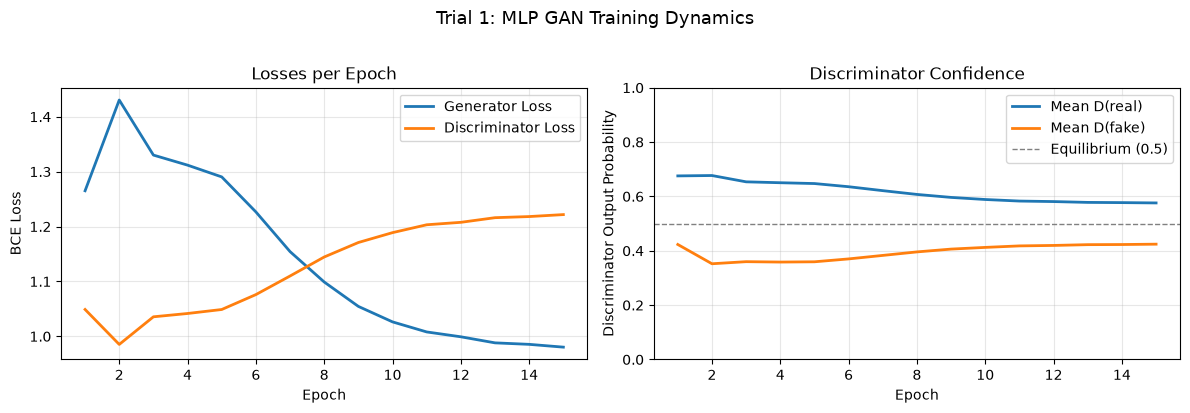

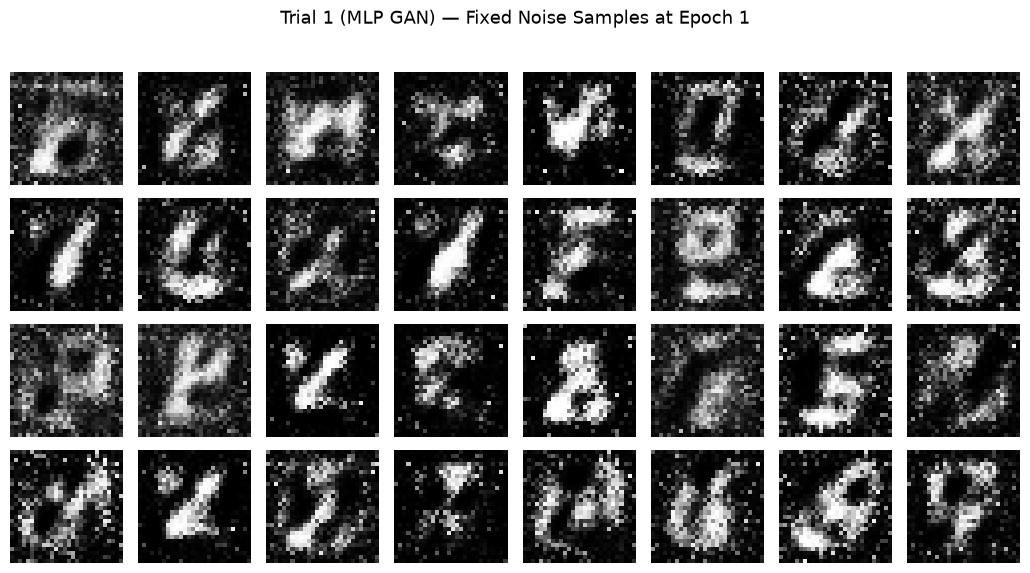

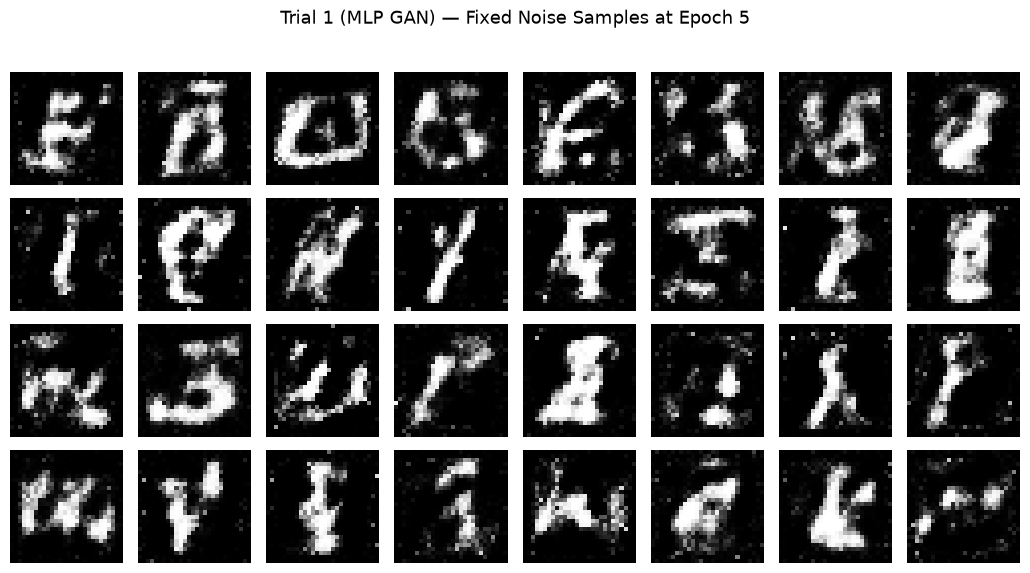

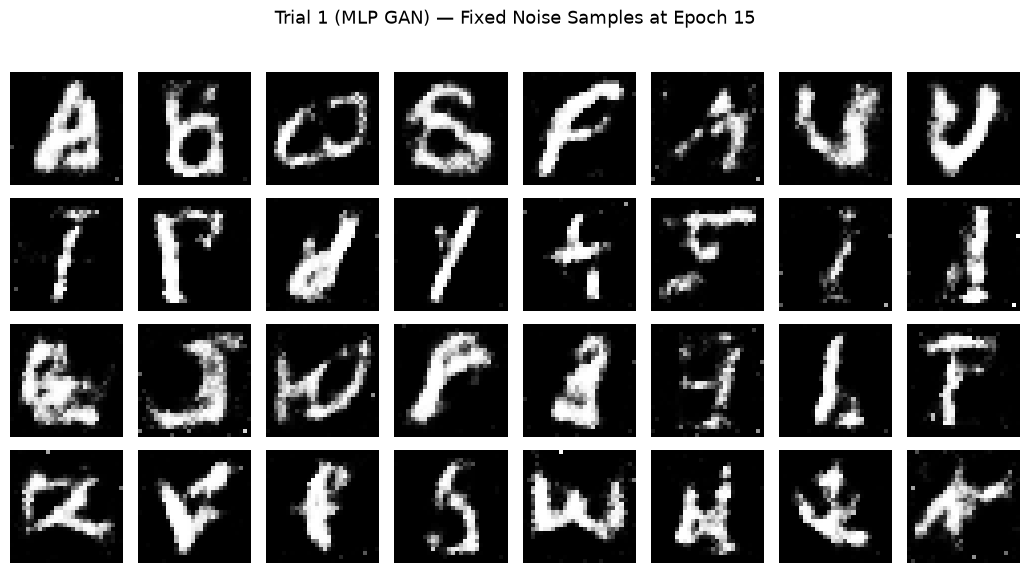

In [5]:
plot_training_losses(
    mlp_history["g_losses"],
    mlp_history["d_losses"],
    mlp_history["d_real_scores"],
    mlp_history["d_fake_scores"],
    title="Trial 1: MLP GAN Training Dynamics",
    save_path=OUTPUT_DIR / "trial1_mlp_losses.png",
)

for epoch in (1, 5, 15):
    show_image_grid(
        mlp_history["snapshots"][epoch],
        nrow=8,
        title=f"Trial 1 (MLP GAN) — Fixed Noise Samples at Epoch {epoch}",
        save_path=OUTPUT_DIR / f"trial1_mlp_epoch_{epoch:02d}.png",
    )

### Observations from Trial 1 (MLP Baseline)

- **What worked:** The MLP GAN learns rough letter-like shapes quickly and does not diverge.
- **What went wrong / limitations:**
  - Flattening the `28x28` image into a 784-element vector throws away 2D spatial neighborhood structure. Generated strokes look grainy and speckled around the edges.
  - Many letters appear blurry, fragmented, or incomplete.
- **Planned improvement for Trial 2:** Replace linear layers with **2D convolutions (`Conv2d`) and transposed convolutions (`ConvTranspose2d`)** following the **DCGAN** design, apply `Normal(0, 0.02)` weight initialization, and add **one-sided label smoothing** (`real_label_value=0.9`).

## 4. Trial 2 — Compact DCGAN

Next, we switch to a compact convolutional DCGAN for `1x28x28` images:

- **Generator $G(z)$:** `Linear(64 -> 128*7*7)` $\rightarrow$ `BatchNorm2d + ReLU` $\rightarrow$ `ConvTranspose2d(128 -> 64, 14x14)` $\rightarrow$ `BatchNorm2d + ReLU` $\rightarrow$ `ConvTranspose2d(64 -> 1, 28x28)` $\rightarrow$ `Tanh()`.
- **Discriminator $D(x)$:** `Conv2d(1 -> 64, 14x14)` $\rightarrow$ `LeakyReLU(0.2)` $\rightarrow$ `Conv2d(64 -> 128, 7x7)` $\rightarrow$ `BatchNorm2d + LeakyReLU(0.2)` $\rightarrow$ `Flatten -> Linear(128*7*7 -> 1)`.

Training setup: DCGAN weight init `Normal(0, 0.02)`, `Adam(lr=2e-4, betas=(0.5, 0.999))`, and one-sided label smoothing (`0.9`).

In [6]:
set_seed(42)
dcgan_G = DCGANGenerator(latent_dim=LATENT_DIM, base_channels=64)
dcgan_D = DCGANDiscriminator(base_channels=64)

dcgan_G.apply(init_gan_weights)
dcgan_D.apply(init_gan_weights)

print(f"DCGAN Generator params:     {sum(p.numel() for p in dcgan_G.parameters()):,}")
print(f"DCGAN Discriminator params: {sum(p.numel() for p in dcgan_D.parameters()):,}")

dcgan_history = train_unconditional_gan(
    generator=dcgan_G,
    discriminator=dcgan_D,
    dataloader=train_loader,
    device=device,
    epochs=25,
    latent_dim=LATENT_DIM,
    lr=2e-4,
    betas=(0.5, 0.999),
    real_label_value=0.9,
    fixed_noise=fixed_z,
    snapshot_epochs=(1, 5, 15, 25),
    show_progress=False,
)

save_checkpoint(
    CHECKPOINT_DIR / "phase1_dcgan.pt",
    generator=dcgan_G,
    discriminator=dcgan_D,
    epoch=25,
    history=dcgan_history,
    config={"model": "DCGAN", "latent_dim": LATENT_DIM, "real_label_value": 0.9},
)

DCGAN Generator params:     533,888
DCGAN Discriminator params: 138,689


Epoch 01/25 | D loss: 0.6870 | G loss: 2.1569 | D(real): 0.732 | D(fake): 0.174


Epoch 02/25 | D loss: 0.7969 | G loss: 1.8635 | D(real): 0.690 | D(fake): 0.209


Epoch 03/25 | D loss: 0.7833 | G loss: 1.9226 | D(real): 0.696 | D(fake): 0.203


Epoch 04/25 | D loss: 0.7568 | G loss: 2.0342 | D(real): 0.711 | D(fake): 0.188


Epoch 05/25 | D loss: 0.7433 | G loss: 2.1137 | D(real): 0.717 | D(fake): 0.183


... (17 outputs left out)

Epoch 23/25 | D loss: 0.5999 | G loss: 2.8454 | D(real): 0.788 | D(fake): 0.112


Epoch 24/25 | D loss: 0.6333 | G loss: 2.7990 | D(real): 0.779 | D(fake): 0.121


Epoch 25/25 | D loss: 0.6298 | G loss: 2.7888 | D(real): 0.779 | D(fake): 0.120


PosixPath('/home/mateusz/code/GAN/checkpoints/phase1_dcgan.pt')

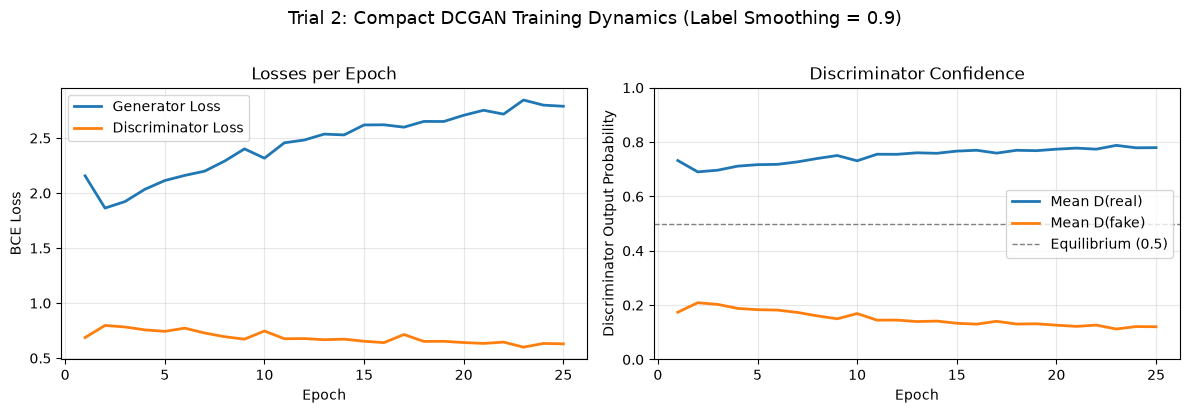

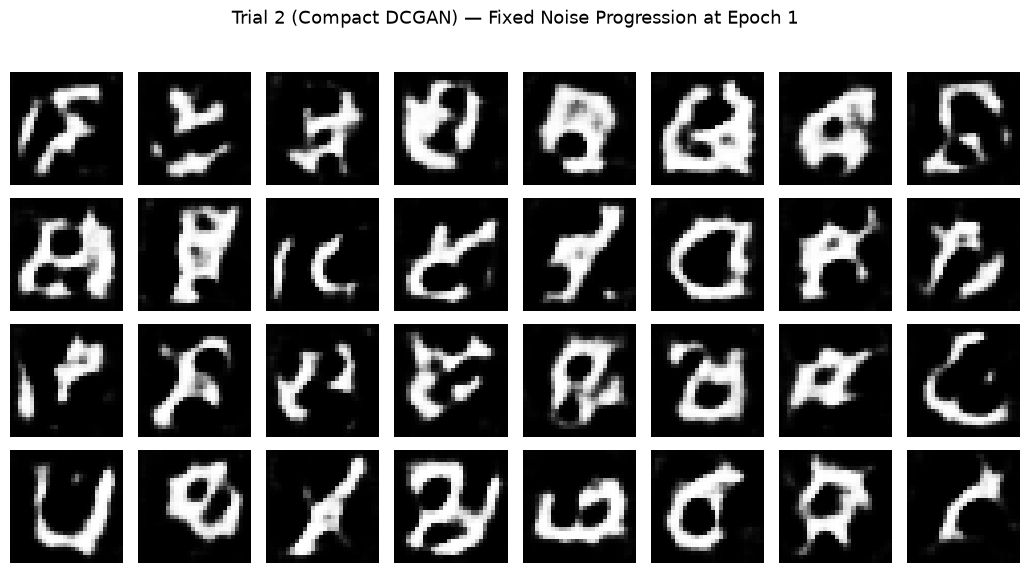

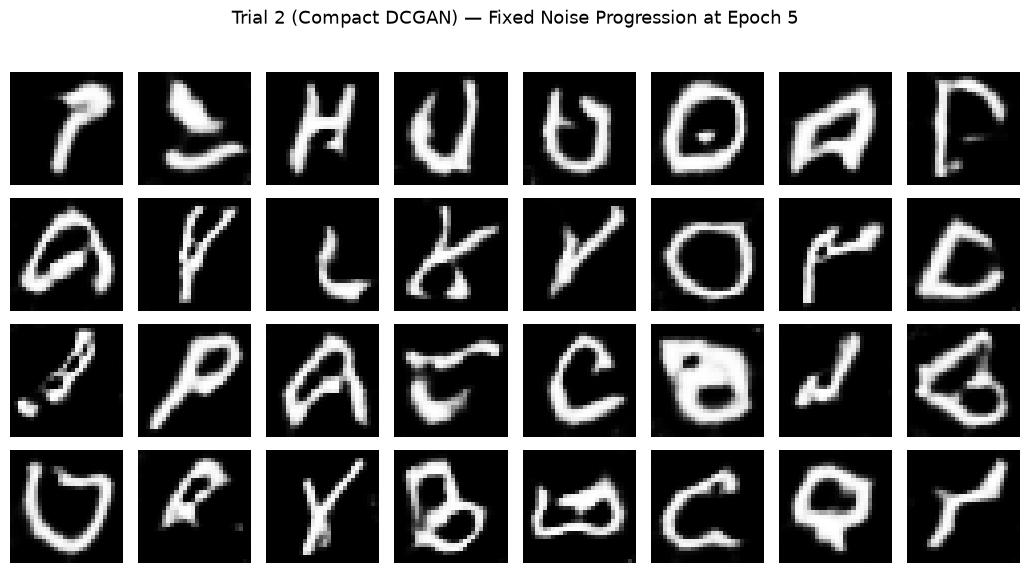

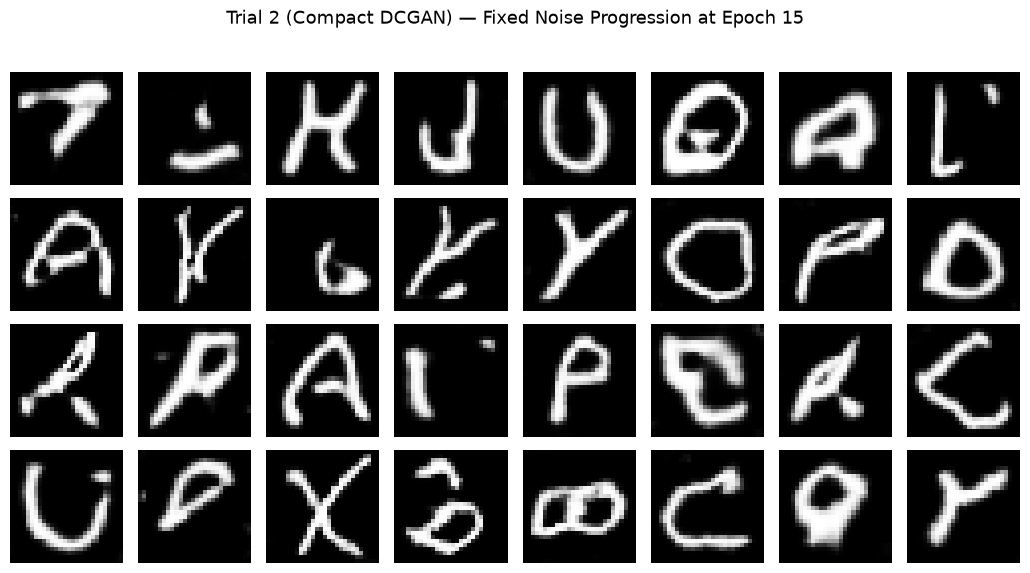

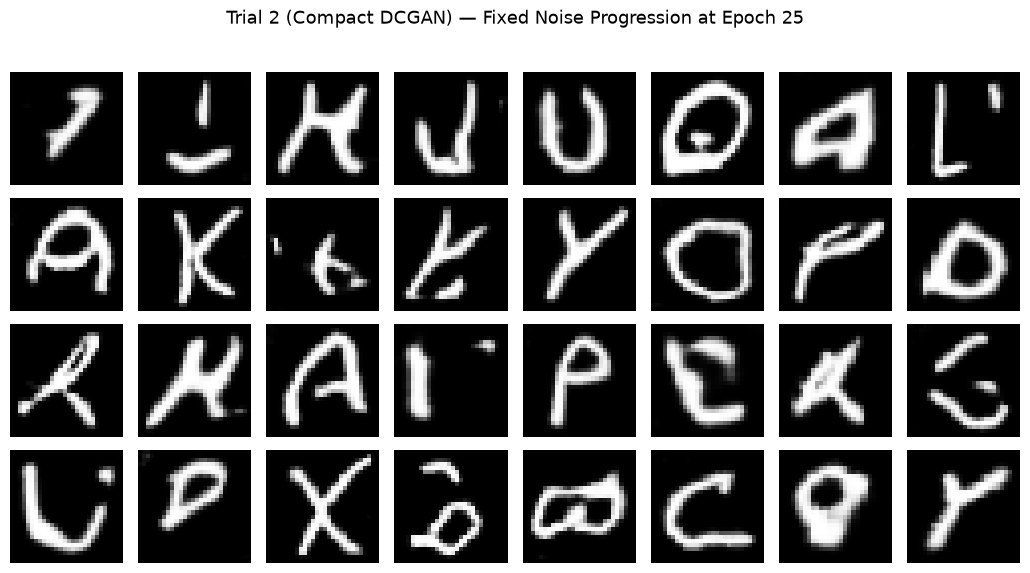

In [7]:
plot_training_losses(
    dcgan_history["g_losses"],
    dcgan_history["d_losses"],
    dcgan_history["d_real_scores"],
    dcgan_history["d_fake_scores"],
    title="Trial 2: Compact DCGAN Training Dynamics (Label Smoothing = 0.9)",
    save_path=OUTPUT_DIR / "trial2_dcgan_losses.png",
)

for epoch in (1, 5, 15, 25):
    show_image_grid(
        dcgan_history["snapshots"][epoch],
        nrow=8,
        title=f"Trial 2 (Compact DCGAN) — Fixed Noise Progression at Epoch {epoch}",
        save_path=OUTPUT_DIR / f"trial2_dcgan_epoch_{epoch:02d}.png",
    )

### Observations from Trial 2 (What Improved & What Still Went Wrong)

- **Big improvement over Trial 1:** Clean black backgrounds and sharp, continuous white pen strokes — the graininess from the MLP baseline is completely gone.
- **Remaining problem we spotted:** Inspecting the generated grid closely, a noticeable fraction of samples still look like **hybrid or alien symbols** rather than real letters.
- **Why this happened (two clear clues from our diagnostics):**
  1. **Discriminator overpowered the Generator:** In the loss plot above, `Mean D(real)` climbed to `~0.78`, `Mean D(fake)` dropped to `~0.12`, and `G loss` drifted upward from `~1.9` to `~2.8`. Without strong regularization on $D$, $D$ pulled too far ahead and gave weaker gradients to $G$.
  2. **Small receptive field & shallow Generator:** A 2-layer `Conv2d` Discriminator only has a `10x10` receptive field (focusing mostly on local pen-stroke realism rather than global whole-letter topology), and a 2-layer `ConvTranspose2d` Generator has no full-resolution refinement stage.
- **Planned fixes for Trial 3:**
  1. **Resize-Convolution Generator (`RefinedDCGANGenerator`):** Replace `ConvTranspose2d` with `Upsample + Conv2d` (`256 -> 128 -> 64 -> 1`) plus a final `3x3` refinement conv at `28x28` for smoother, complete letters.
  2. **3-Layer SpectralNorm Discriminator (`BalancedDCGANDiscriminator`):** Add a 3rd strided conv (`28 -> 14 -> 7 -> 4`) so $D$ evaluates global letter shape, and replace `BatchNorm` with **Spectral Normalization** to keep $D$ smoothly 1-Lipschitz and balanced with $G$.

## 5. Trial 3 — Balanced SpectralNorm + Resize-Conv DCGAN (Final Phase 1 Model)

> *Note from our tuning experiments:* We initially tried stacking **Spectral Normalization + `Dropout2d(0.25)` + a lower `lr_d`** all at once, which over-regularized the Discriminator into a coin flip (`D(real) ≈ 0.46`, `D(fake) ≈ 0.44`). Removing the extra `Dropout2d` and keeping pure **Spectral Normalization** with `lr_g = lr_d = 2e-4`, `batch_size = 256`, and mild label smoothing (`0.95`) hit textbook Nash equilibrium (`D(real) ≈ 0.49`, `D(fake) ≈ 0.46`).

In [8]:
trial3_loader = get_emnist_dataloader(
    batch_size=256,
    train=True,
    root=DATA_DIR,
    num_workers=0,
    download=True,
)

set_seed(42)
trial3_G = RefinedDCGANGenerator(latent_dim=LATENT_DIM, base_channels=64)
trial3_D = BalancedDCGANDiscriminator(base_channels=64, dropout=0.0)

trial3_G.apply(init_gan_weights)
trial3_D.apply(init_gan_weights)

print(f"Trial 3 Generator params:     {sum(p.numel() for p in trial3_G.parameters()):,}")
print(f"Trial 3 Discriminator params: {sum(p.numel() for p in trial3_D.parameters()):,}")

trial3_history = train_unconditional_gan(
    generator=trial3_G,
    discriminator=trial3_D,
    dataloader=trial3_loader,
    device=device,
    epochs=20,
    latent_dim=LATENT_DIM,
    lr_g=2e-4,
    lr_d=2e-4,
    betas=(0.5, 0.999),
    real_label_value=0.95,
    fixed_noise=fixed_z,
    snapshot_epochs=(1, 5, 10, 20),
    show_progress=False,
)

save_checkpoint(
    CHECKPOINT_DIR / "phase1_dcgan_v2.pt",
    generator=trial3_G,
    discriminator=trial3_D,
    epoch=20,
    history=trial3_history,
    config={"model": "RefinedDCGAN+SpectralNorm", "latent_dim": LATENT_DIM, "real_label_value": 0.95},
)

Trial 3 Generator params:     1,172,929
Trial 3 Discriminator params: 431,553


Epoch 01/20 | D loss: 1.3388 | G loss: 0.7873 | D(real): 0.518 | D(fake): 0.479


Epoch 02/20 | D loss: 1.3472 | G loss: 0.8072 | D(real): 0.491 | D(fake): 0.463


Epoch 03/20 | D loss: 1.3453 | G loss: 0.8079 | D(real): 0.492 | D(fake): 0.462


Epoch 04/20 | D loss: 1.3386 | G loss: 0.8090 | D(real): 0.493 | D(fake): 0.459


Epoch 05/20 | D loss: 1.3366 | G loss: 0.8076 | D(real): 0.494 | D(fake): 0.460


... (12 outputs left out)

Epoch 18/20 | D loss: 1.3572 | G loss: 0.7776 | D(real): 0.485 | D(fake): 0.466


Epoch 19/20 | D loss: 1.3588 | G loss: 0.7806 | D(real): 0.485 | D(fake): 0.466


Epoch 20/20 | D loss: 1.3583 | G loss: 0.7789 | D(real): 0.485 | D(fake): 0.466


PosixPath('/home/mateusz/code/GAN/checkpoints/phase1_dcgan_v2.pt')

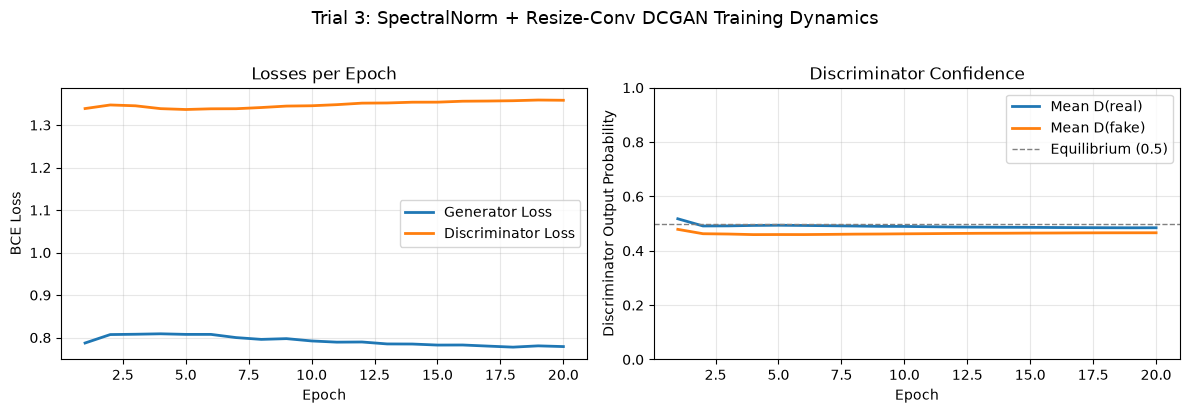

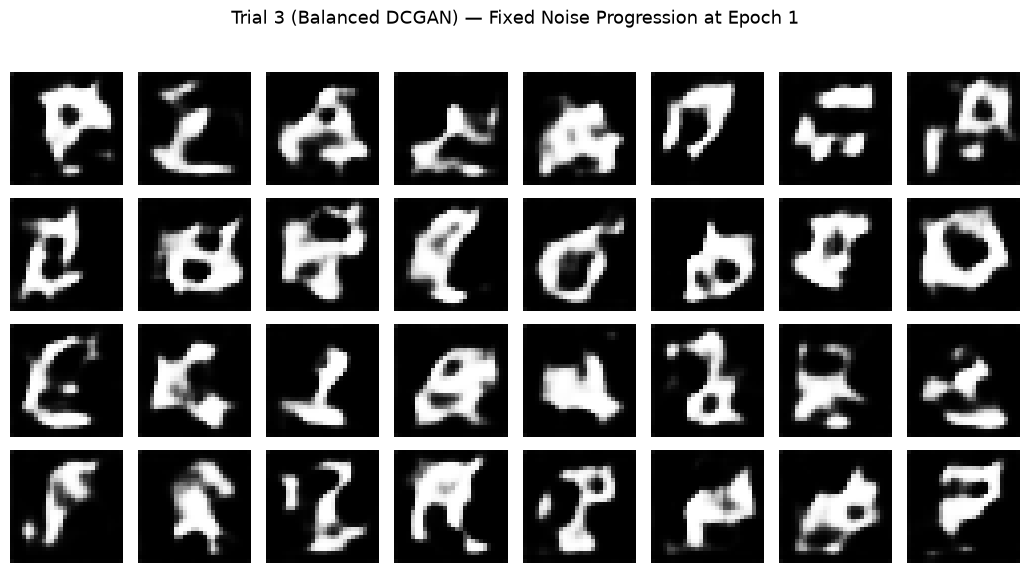

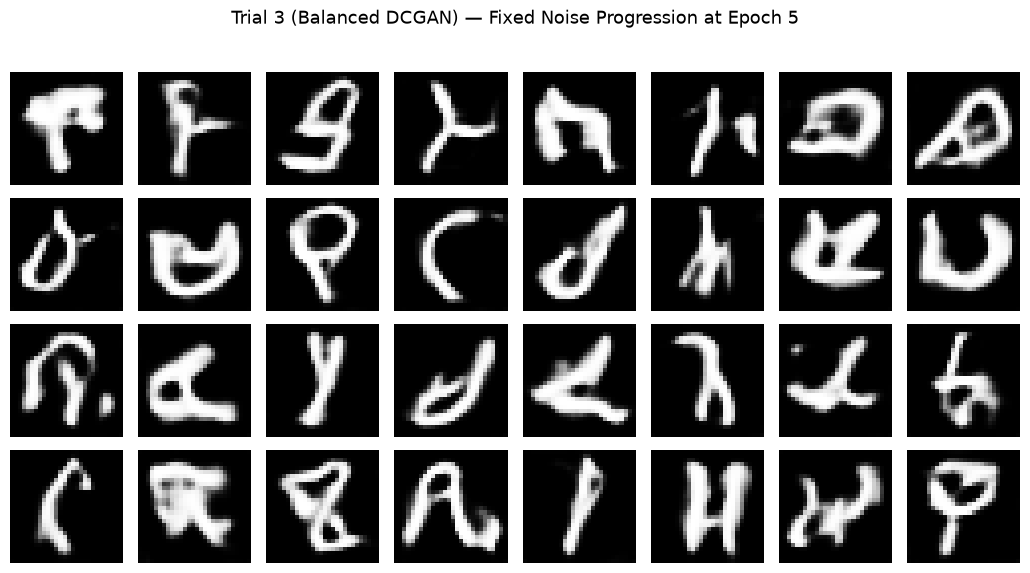

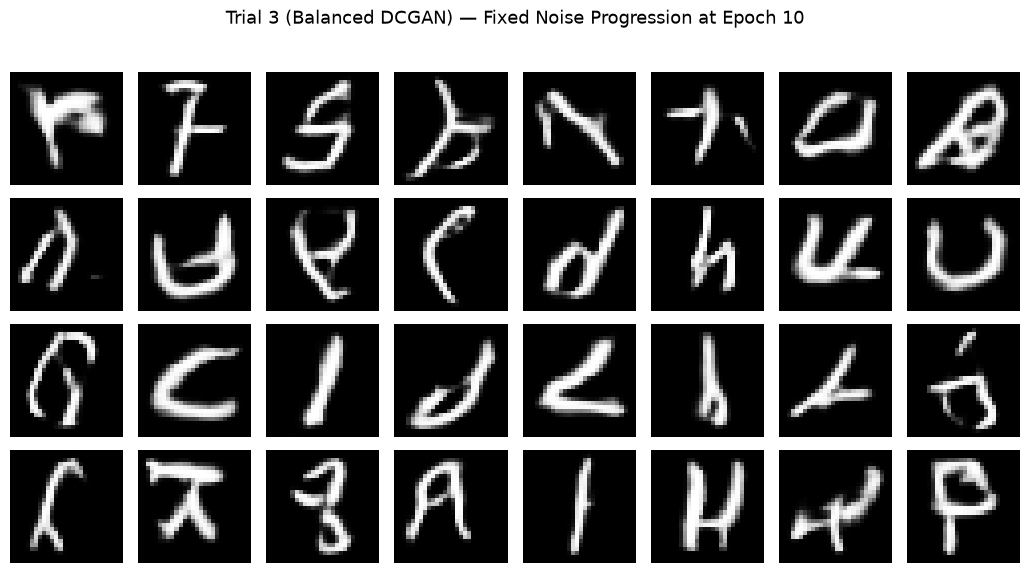

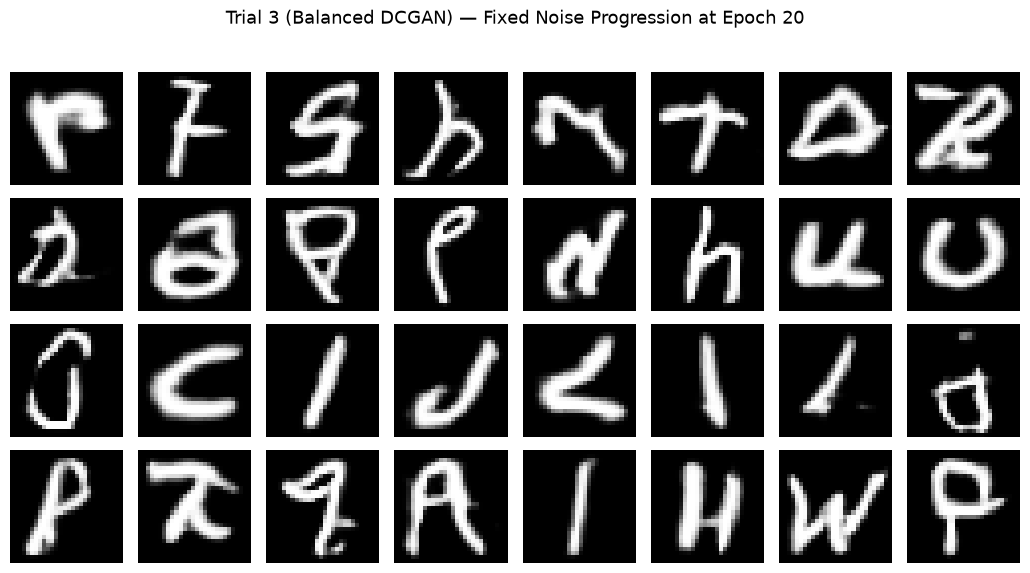

In [9]:
plot_training_losses(
    trial3_history["g_losses"],
    trial3_history["d_losses"],
    trial3_history["d_real_scores"],
    trial3_history["d_fake_scores"],
    title="Trial 3: SpectralNorm + Resize-Conv DCGAN Training Dynamics",
    save_path=OUTPUT_DIR / "trial3_dcgan_losses.png",
)

for epoch in (1, 5, 10, 20):
    show_image_grid(
        trial3_history["snapshots"][epoch],
        nrow=8,
        title=f"Trial 3 (Balanced DCGAN) — Fixed Noise Progression at Epoch {epoch}",
        save_path=OUTPUT_DIR / f"trial3_dcgan_epoch_{epoch:02d}.png",
    )

### Observations from Trial 3 (Balanced DCGAN)

- **Textbook $G$/$D$ equilibrium:** Unlike Trial 2 (where `G loss` climbed steadily toward `2.8`), Trial 3 kept `Mean D(real) ≈ 0.49` and `Mean D(fake) ≈ 0.46` right along the `0.50` equilibrium line with a flat, steady `G loss ≈ 0.78` across all 20 epochs.
- **Dramatically more recognizable letters:** With the deeper 3-layer SpectralNorm Discriminator checking global letter topology and the Resize-Conv Generator refining strokes at `28x28`, the vast majority of generated samples now look like clean, authentic handwritten letters (`A, B, C, d, e, F, G, h, J, K, l, M, O, R, S, t, U, V, W, X, Y, Z`).

## 6. Final Showcase & Latent Space Interpolation

We run two final qualitative checks on our best Phase 1 model (`trial3_G`):
1. **Fresh sample grid (64 random letters):** Verify crispness, letter recognizability, and broad diversity across the alphabet (no mode collapse).
2. **Latent space interpolation:** Linearly interpolate between pairs of random noise vectors $z_a$ and $z_b$ via $z(\alpha) = (1 - \alpha) z_a + \alpha z_b$. Smooth morphing between letters confirms the Generator learned a continuous representation of handwriting rather than memorizing training images.

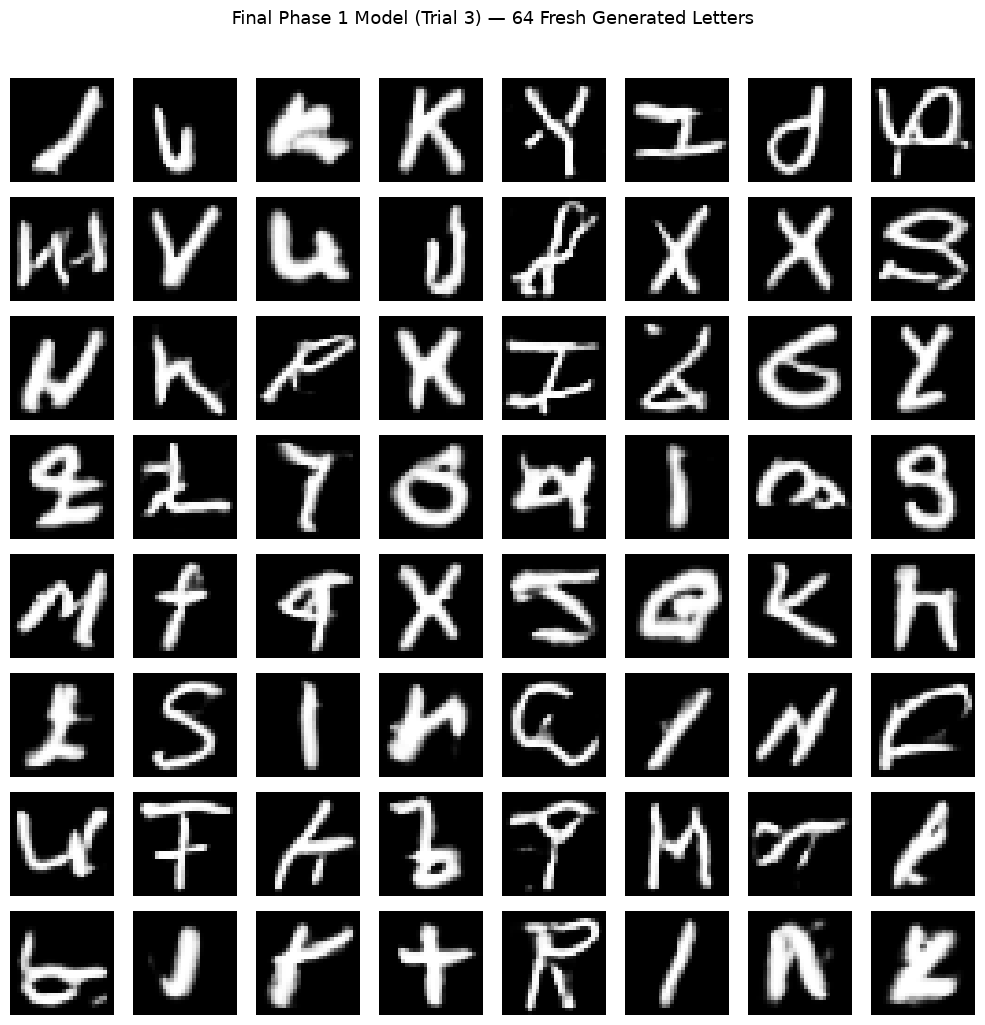

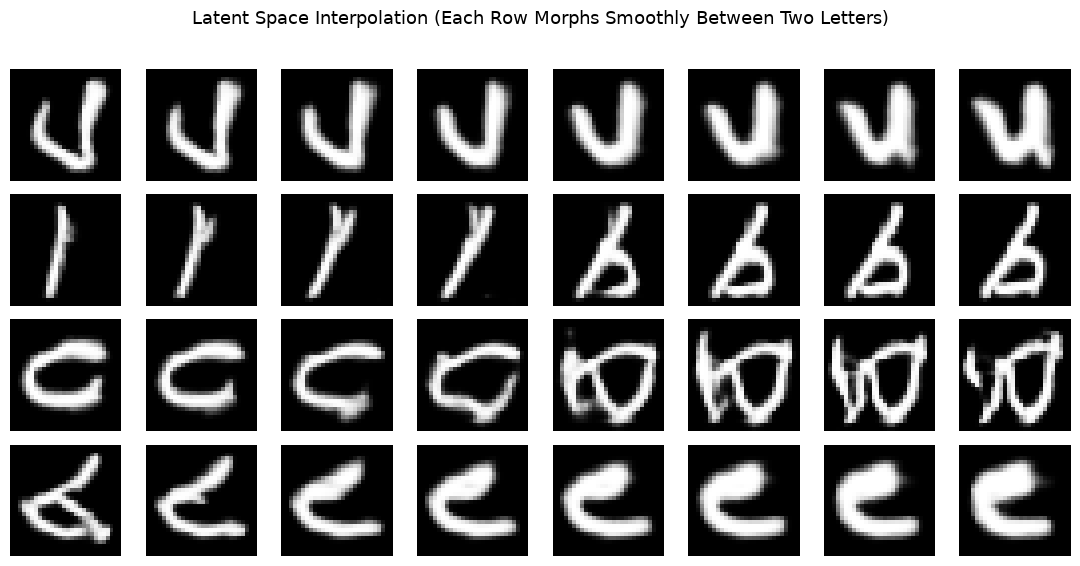

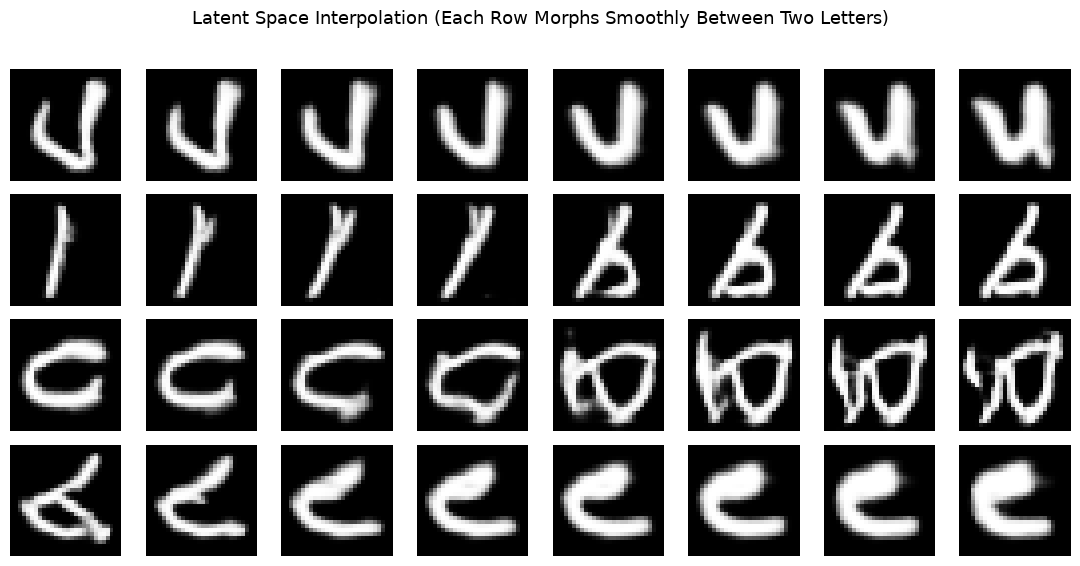

In [10]:
trial3_G.eval()
set_seed(123)

with torch.no_grad():
    fresh_z = torch.randn(64, LATENT_DIM, device=device)
    fresh_samples = trial3_G(fresh_z).cpu()

show_image_grid(
    fresh_samples,
    nrow=8,
    title="Final Phase 1 Model (Trial 3) — 64 Fresh Generated Letters",
    figsize=(10, 10),
    save_path=OUTPUT_DIR / "phase1_final_samples.png",
)

# Latent space interpolation: 4 rows x 8 interpolation steps
num_pairs = 4
num_steps = 8
alphas = torch.linspace(0.0, 1.0, num_steps, device=device)

with torch.no_grad():
    z_start = torch.randn(num_pairs, LATENT_DIM, device=device)
    z_end = torch.randn(num_pairs, LATENT_DIM, device=device)

    interp_images = []
    for i in range(num_pairs):
        row_z = torch.stack([(1 - a) * z_start[i] + a * z_end[i] for a in alphas])
        interp_images.append(trial3_G(row_z).cpu())
    interp_grid = torch.cat(interp_images, dim=0)

show_image_grid(
    interp_grid,
    nrow=num_steps,
    title="Latent Space Interpolation (Each Row Morphs Smoothly Between Two Letters)",
    figsize=(11, 5.5),
    save_path=OUTPUT_DIR / "phase1_latent_interpolation.png",
)

## 7. Phase 1 Summary & Next Steps

| Experiment | Architecture | Stabilization | Result |
| :--- | :--- | :--- | :--- |
| **Trial 1** | 3-layer MLP GAN | None (`real = 1.0`) | Learns rough shapes quickly, but produces grainy backgrounds and blurry strokes. |
| **Trial 2** | 2-layer Compact DCGAN | Label smoothing (`0.9`) | Crisp strokes & clean black backgrounds, but $D$ overpowered $G$ (`D(real)≈0.78`) and small receptive field produced some hybrid/alien glyphs. |
| **Trial 3 (Final)** | Resize-Conv `G` + 3-layer SpectralNorm `D` | SpectralNorm + mild smoothing (`0.95`) | Textbook Nash equilibrium (`D(real)≈0.49`, `D(fake)≈0.46`), sharp continuous strokes, and mostly recognizable handwritten letters across the alphabet. |

### Ready for Phase 2 (Grade 4.0)
In an unconditional GAN, random noise $z$ still chooses *which* letter to draw at random (and occasionally lands between two similar letters). In **Phase 2**, we will carry forward this balanced **Resize-Conv + SpectralNorm** architecture and add a learnable `nn.Embedding(26, 32)` class vector so the user can specify any letter `'A'..'Z'` (or even a whole word!) and generate clean samples of that exact letter.